In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


### Step 1: Load the clean data
We read `cleaned_data.csv` created in Notebook 2.
`MAIN` is the list of 5 cities with 5+ years of data. Bhopal is kept separate.

In [4]:
clean_data= pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Air_Quality_Index(AQI)_Projrct\01_Data\raw\city_day.csv\city_day.csv")
clean_data.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:
clean_data.shape

(29531, 16)

In [7]:
clean_data.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

### Step 2: Yearly trend
Average AQI of each city for every year. It shows whether pollution is rising or falling.
Years with very few days of data (like 2020, which ends in July) should be read carefully.

In [11]:
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]

In [13]:
clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])

def aqi_category(v):
    if v <= 50:  return "Good"
    if v <= 100: return "Satisfactory"
    if v <= 200: return "Moderate"
    if v <= 300: return "Poor"
    if v <= 400: return "Very Poor"
    return "Severe"

def season(m):
    if m in (12, 1, 2):   return "Winter"
    if m in (3, 4, 5):    return "Summer"
    if m in (6, 7, 8, 9): return "Monsoon"
    return "Post-monsoon"

clean["Year"]         = clean["Date"].dt.year
clean["Month"]        = clean["Date"].dt.month
clean["Season"]       = clean["Month"].apply(season)
clean["AQI_Category"] = clean["AQI"].apply(aqi_category)

print(clean.columns.tolist())

['Date', 'City', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'AQI_Category', 'Year', 'Month', 'Season']


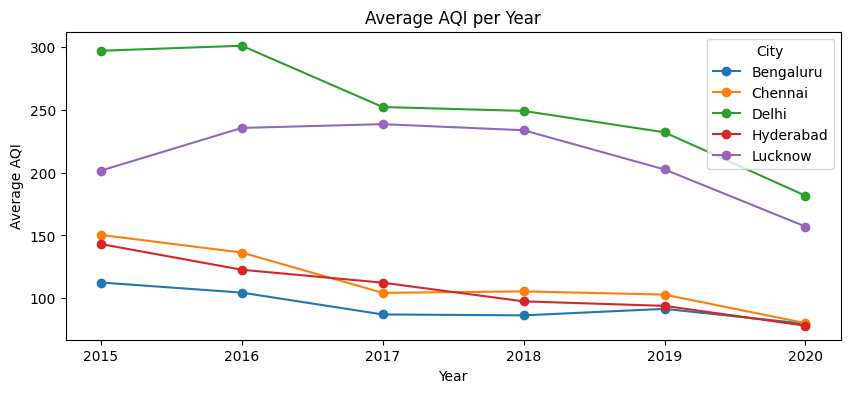

City,Bengaluru,Chennai,Delhi,Hyderabad,Lucknow
Year,,,,,
2015,113.0,150.0,297.0,143.0,202.0
2016,105.0,136.0,301.0,123.0,236.0
2017,87.0,104.0,252.0,112.0,239.0
2018,86.0,105.0,249.0,98.0,234.0
2019,92.0,103.0,232.0,94.0,203.0
2020,80.0,80.0,182.0,78.0,157.0


In [14]:
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]

yearly = clean[clean["City"].isin(MAIN)].groupby(["Year", "City"])["AQI"].mean().unstack()
yearly.plot(marker="o", figsize=(10, 4), title="Average AQI per Year")
plt.ylabel("Average AQI")
plt.show()
yearly.round(0)

In [15]:
clean.to_csv("../01_Data/processed/cleaned_data.csv", index=False)
print("Saved with columns:", clean.columns.tolist())

Saved with columns: ['Date', 'City', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'AQI_Category', 'Year', 'Month', 'Season']


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]

# agar columns file me nahi hain to yahan bana lo
if "Year" not in clean.columns:
    clean["Year"] = clean["Date"].dt.year
if "Month" not in clean.columns:
    clean["Month"] = clean["Date"].dt.month
if "Season" not in clean.columns:
    def season(m):
        if m in (12, 1, 2):   return "Winter"
        if m in (3, 4, 5):    return "Summer"
        if m in (6, 7, 8, 9): return "Monsoon"
        return "Post-monsoon"
    clean["Season"] = clean["Month"].apply(season)
if "AQI_Category" not in clean.columns:
    def aqi_category(v):
        if v <= 50:  return "Good"
        if v <= 100: return "Satisfactory"
        if v <= 200: return "Moderate"
        if v <= 300: return "Poor"
        if v <= 400: return "Very Poor"
        return "Severe"
    clean["AQI_Category"] = clean["AQI"].apply(aqi_category)

print(clean.shape)
print(clean["City"].value_counts())

(9964, 20)
City
Delhi        2009
Bengaluru    1930
Lucknow      1920
Chennai      1913
Hyderabad    1907
Bhopal        285
Name: count, dtype: int64


#### Step 3: AQI category share: How often is the air in each category?
* For each city we calculate the **percentage of days** in Good, Satisfactory, Moderate, Poor, Very Poor and Severe.
* This shows how serious the pollution problem is in each city, not just the average.

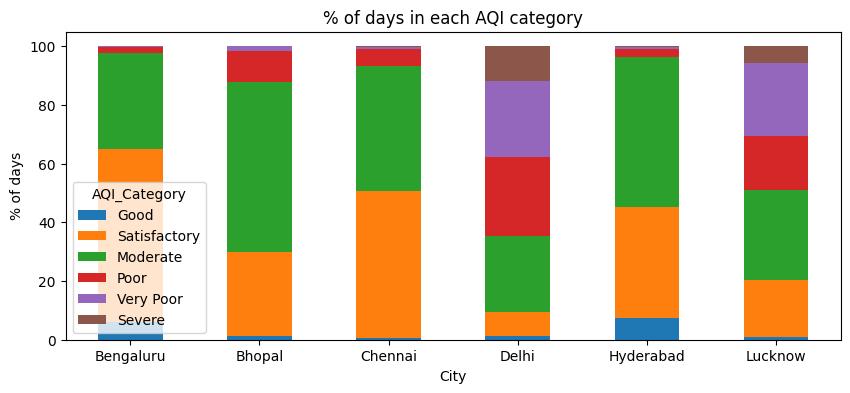

AQI_Category,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
City,,,,,,
Bengaluru,6.2,58.9,32.8,1.9,0.3,0.0
Bhopal,1.4,28.4,57.9,10.9,1.4,0.0
Chennai,0.6,50.1,42.4,5.8,0.7,0.4
Delhi,1.1,8.2,25.9,27.0,25.9,11.9
Hyderabad,7.4,37.7,51.1,2.8,0.5,0.4
Lucknow,0.8,19.5,30.8,18.4,24.7,5.8


In [17]:
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
share = pd.crosstab(clean["City"], clean["AQI_Category"], normalize="index") * 100
share = share.reindex(columns=[c for c in order if c in share.columns])

share.plot(kind="bar", stacked=True, figsize=(10, 4), title="% of days in each AQI category")
plt.ylabel("% of days")
plt.xticks(rotation=0)
plt.show()
share.round(1)

## Step 4: Seasonal pattern
Average AQI in each season. This confirms the yearly pattern that ARIMA and Prophet will learn.
Seasons used: Winter (Dec to Feb), Summer (Mar to May), Monsoon (Jun to Sep), Post-monsoon (Oct, Nov).

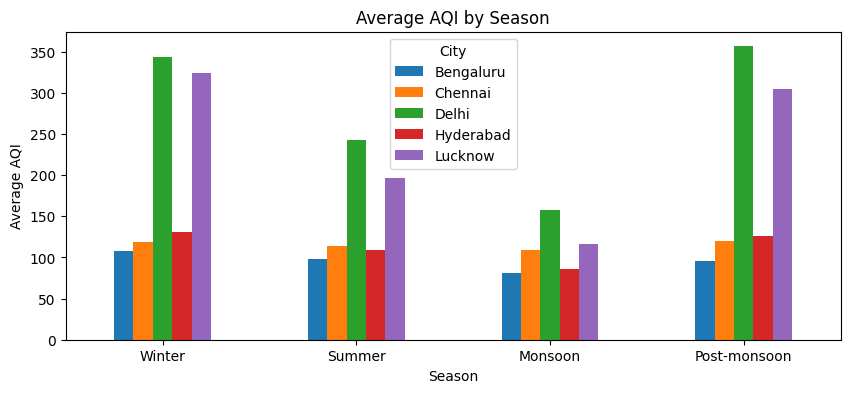

City,Bengaluru,Chennai,Delhi,Hyderabad,Lucknow
Season,,,,,
Winter,108.0,119.0,343.0,131.0,324.0
Summer,98.0,114.0,243.0,109.0,196.0
Monsoon,81.0,109.0,158.0,86.0,116.0
Post-monsoon,96.0,120.0,356.0,126.0,305.0


In [18]:
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
seasonal = (clean[clean["City"].isin(MAIN)]
            .groupby(["Season", "City"])["AQI"].mean().unstack().loc[season_order])

seasonal.plot(kind="bar", figsize=(10, 4), title="Average AQI by Season")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.show()
seasonal.round(0)

### **Observation:** (write from your table)
- AQI is highest in ______ and lowest in ______.
- The gap between seasons is largest in ______ (for example Delhi).

#### Step 5: Which pollutant moves with AQI? (correlation)
A value close to **1** means two columns rise and fall together. A value near 0 means no link.
We use Delhi because it has the most data. This also supports the explainability feature of our app.

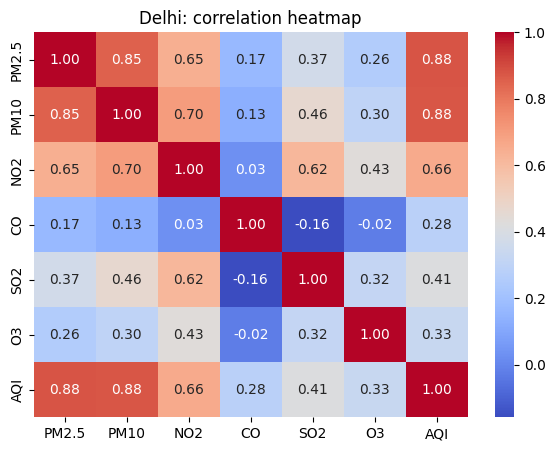

In [20]:
cols = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3", "AQI"]
plt.figure(figsize=(7, 5))
sns.heatmap(clean[clean["City"] == "Delhi"][cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Delhi: correlation heatmap")
plt.show()

### **Observation:** (look at the AQI row/column)
- ______ and ______ have the strongest link with AQI (close to 1).
- ______ has a weak link with AQI.

#### ## Step 6: Festival impact (Diwali and Holi)
For each festival we compare:
- **Before:** average AQI of the 7 days before the festival
- **After:** average AQI of the 3 days after the festival

A positive change means AQI went up after the festival.

**Important:** this shows a *link*, not proof. Diwali comes just before winter, so cold weather also raises AQI.
Our data ends in July 2020, so Diwali 2020 is not included.

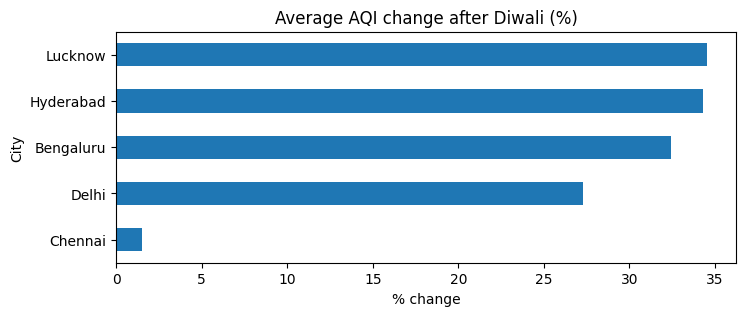

City,Bengaluru,Chennai,Delhi,Hyderabad,Lucknow
Year,,,,,
2015,83.7,-20.3,7.8,30.6,45.3
2016,-56.9,-58.8,13.6,4.2,48.3
2017,82.6,-0.8,42.7,32.2,8.3
2018,23.7,33.6,19.5,44.3,38.2
2019,28.7,54.0,52.7,60.2,32.4


In [ ]:
diwali = ["2015-11-11", "2016-10-30", "2017-10-19", "2018-11-07", "2019-10-27"]
holi   = ["2015-03-06", "2016-03-24", "2017-03-13", "2018-03-02", "2019-03-21", "2020-03-10"]

def festival_effect(dates, cities):
    rows = []
    for city in cities:
        s = clean[clean["City"] == city].set_index("Date")["AQI"].sort_index()
        for d in pd.to_datetime(dates):
            before = s.loc[d - pd.Timedelta(days=7): d - pd.Timedelta(days=1)].mean()
            after  = s.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(days=3)].mean()
            rows.append({"City": city, "Year": d.year, "Before": before, "After": after})
    r = pd.DataFrame(rows).dropna()
    r["Change_%"] = ((r["After"] - r["Before"]) / r["Before"] * 100).round(1)
    return r

diwali_df = festival_effect(diwali, MAIN)
diwali_df.groupby("City")["Change_%"].mean().round(1).sort_values().plot(
    kind="barh", figsize=(8, 3), title="Average AQI change after Diwali (%)")
plt.xlabel("% change")
plt.show()
diwali_df.pivot(index="Year", columns="City", values="Change_%")

##### holi

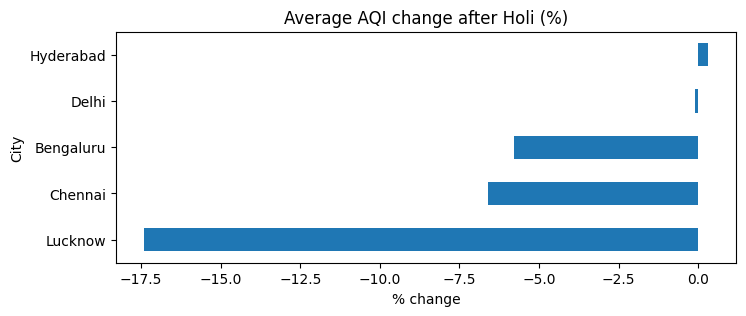

City,Bengaluru,Chennai,Delhi,Hyderabad,Lucknow
Year,,,,,
2015,NaN,NaN,-36.6,NaN,NaN
2016,-18.3,-36.8,21.7,28.9,10.0
2017,-18.0,29.2,75.3,-9.7,-25.5
2018,14.1,-13.4,-22.7,-1.2,-31.0
2019,7.3,-9.6,-38.0,4.6,-36.7
2020,-14.3,-2.4,-0.4,-21.1,-3.8


In [22]:
holi_df = festival_effect(holi, MAIN)
holi_df.groupby("City")["Change_%"].mean().round(1).sort_values().plot(
    kind="barh", figsize=(8, 3), title="Average AQI change after Holi (%)")
plt.xlabel("% change")
plt.show()
holi_df.pivot(index="Year", columns="City", values="Change_%")

#### Step 7 (Bonus): COVID-19 lockdown effect
India's lockdown started on 25 March 2020. We compare **25 March to 30 April** of 2019 and 2020.
Traffic and industry were mostly shut in 2020, so this shows how human activity affects air quality.

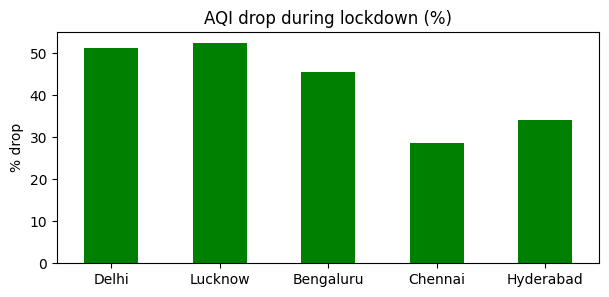

,2019,2020,Drop_%
Delhi,216.9,106.0,51.1
Lucknow,221.8,105.8,52.3
Bengaluru,125.3,68.4,45.4
Chennai,86.8,62.0,28.6
Hyderabad,99.1,65.4,34.0


In [23]:
def avg(city, year):
    s = clean[(clean["City"] == city) &
              (clean["Date"] >= f"{year}-03-25") & (clean["Date"] <= f"{year}-04-30")]
    return s["AQI"].mean()

covid = pd.DataFrame({"2019": [avg(c, 2019) for c in MAIN],
                      "2020": [avg(c, 2020) for c in MAIN]}, index=MAIN).round(1)
covid["Drop_%"] = ((covid["2019"] - covid["2020"]) / covid["2019"] * 100).round(1)

covid["Drop_%"].plot(kind="bar", figsize=(7, 3), title="AQI drop during lockdown (%)", color="green")
plt.ylabel("% drop")
plt.xticks(rotation=0)
plt.show()
covid

**Observation:** (write from your table)
- AQI fell by ____% to ____% in different cities during the lockdown.
- The fall was largest in ______.
- This shows that traffic, industry and construction are major sources of pollution.